# MCDI505 · Semana 2 — Modelos clásicos (ARIMA / SARIMA)

**Estudiante:** Roberto Moncada · 
**Programa:** Magíster en Ciencia de Datos, UNAB Online
**Curso:** MCDI505, Unidad 2, Semana 2 · 
**Archivo:** `mcdi505_f2rmoncada.ipynb` · 
**Fecha:** Octubre de 2026

Este es el único notebook de la semana. El **miércoles** entregue la Hoja de decisiones completa (Formativa 2); el **domingo** entregue este mismo archivo terminado, con la hoja corregida según la retroalimentación (Sumativa 2).


## Hoja de decisiones

| Criterio | Decisión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Estacionariedad y transformaciones | Transformar con **logaritmo** y elegir d y D con una regla fija: la menor diferenciación cuyos tests ADF (Dickey y Fuller, 1979) y KPSS (Kwiatkowski et al., 1992) digan «estacionaria» y cuyo ACF(12) sea menor que 0,5. Valores finales: **d = 1 y D = 1**. | Tabla 1 y Figura 2: en nivel (log), ADF p = 0,391 y KPSS p = 0,100 (no concluyente; ACF(12) = 0,62); con d = 1 y D = 1, ADF p < 0,001, KPSS p = 0,100 y ACF(12) = -0,30 (estacionaria). λ de Box-Cox (Box y Cox, 1964) = 0,00, con IC 95 % de -1,45 a 1,49; elasticidad de la variabilidad anual respecto del nivel = 0,25 (sin 2020-2021) | Dejar la serie sin transformar: el IC de λ también incluye 1, pero con logaritmo los efectos se leen en porcentaje. Diferenciar más de lo necesario (sobrediferenciación) | Los pronósticos hay que volver a pasarlos a GWh con la exponencial; se pierden d + 12·D observaciones al inicio |
| 2. Identificación y estimación | Siete candidatos de las familias AR, MA, ARMA, ARIMA y SARIMA: el sugerido por la ACF/PACF (A), el modelo «airline» SARIMA(0,d,1)(0,D,1)₁₂ (B), un ARMA(1,1) sobre la serie diferenciada (C), un ARIMA sin parte estacional como referencia (D), un AR(1) y un MA(1) puros (E y F) y un SARIMA con AR estacional (G), por el rezago 24 de la PACF. Todos con el indicador `covid` como regresor | Figura 3 (Box et al., 2015): con banda ±0,22, solo el rezago 12 es significativo en la ACF (-0,30) y el 12 y el 24 en la PACF, lo que sugiere SARIMA(0,1,0)(0,1,1)₁₂. Tabla 2: efecto del COVID-19 de -4,2 % a -6,7 % en los modelos con diferenciación estacional (A, B, C, E, F y G); término MA en la frontera de invertibilidad en A, B y C (mín. \|raíz MA\| de 1,002 a 1,013) | Modelos más grandes (más parámetros AR/MA), que ajustan un poco mejor pero se sobreajustan con solo 96 datos | El ARIMA sin estacionalidad sirve para medir cuánto aporta la parte estacional |
| 3. Selección y comparación | Elegir, entre los modelos con la misma diferenciación, el de mejor puntaje promedio en AIC (Akaike, 1974), BIC (Schwarz, 1978) y RMSE y MAE con origen móvil (pronósticos de 2021, 2022 y 2023), siempre que supere al naive estacional en RMSE móvil y pase Ljung-Box en los rezagos 12 y 24; si hay empate, el de menor BIC. *Ajuste respecto de la versión anterior: con solo la validación 2023, A, B y C empataban en puntaje* | Tabla 3: A tiene el mejor puntaje (RMSE móvil 5,78 GWh), pero no pasa Ljung-Box (p = 0,019 en el rezago 24). C, E, F y G tampoco pasan Ljung-Box en el rezago 24 (p de 0,003 a 0,047). Se elige B: RMSE móvil 7,12 frente a 7,72 GWh del naive (7,8 % menos) y MAE móvil 6,64 frente a 6,66 GWh. Figura 4: pronósticos de 2023 | Elegir solo por AIC o solo por RMSE, o validar con un único año (2023), que dejaba a A, B y C empatados | El modelo elegido se usará para el diagnóstico de residuos y, en la siguiente etapa, para pronosticar |
| 4. Diagnóstico de residuos | Revisar autocorrelación con Ljung-Box en los rezagos 12 y 24 (Ljung y Box, 1978), normalidad con Jarque-Bera (Jarque y Bera, 1987) y Shapiro-Wilk (Shapiro y Wilk, 1965), y homocedasticidad con ARCH-LM (Engle, 1982) | Tabla 4 y Figura 5: Ljung-Box p = 0,355 (rezago 12) y p = 0,061 (rezago 24); Jarque-Bera p = 0,001 y Shapiro-Wilk p = 0,019 (no hay normalidad); ARCH-LM p = 0,639 y F p = 0,246 (varianza estable). Sin marzo-junio de 2020, Jarque-Bera p = 0,215; cobertura del intervalo de predicción del 95 % en el origen móvil = 94,4 % | Dar el modelo por válido solo porque tiene buen RMSE | La falta de normalidad se concentra en el inicio del COVID-19; los intervalos de 95 % son aproximados, pero su cobertura real fue cercana al 95 % |


## 0. Configuración y datos

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")        # se ocultan avisos de convergencia para leer mejor el informe
SEMILLA = 505
np.random.seed(SEMILLA)

df = pd.read_csv("consumo_electrico_litoral_depurado.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]

# Partición oficial: 2024 no se utiliza esta semana
y_train = y["2015-01":"2022-12"]
y_val   = y["2023-01":"2023-12"]
print(f"Entrenamiento: {y_train.index.min():%Y-%m} a {y_train.index.max():%Y-%m} ({len(y_train)} obs.)")
print(f"Validación:    {y_val.index.min():%Y-%m} a {y_val.index.max():%Y-%m} ({len(y_val)} obs.)")

# ---- Preparación adicional (no cambia la partición) ----
S = 12                                                        # periodo estacional (meses)
covid = df["covid"].astype(float)                             # indicador oficial: mar-2020 a dic-2021
tiempo = pd.Series(np.arange(len(df)) / 12.0, index=df.index, name="tiempo")   # tiempo en años (para el "drift")
ROJO, AZUL, VERDE, GRIS, NEGRO = "#b30338", "#0057b8", "#2e7d32", "#9e9e9e", "#222222"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
pd.set_option("display.float_format", lambda x: f"{x:.3f}".replace(".", ","))   # coma decimal en las tablas
pd.set_option("display.max_colwidth", None)                                     # textos de tabla completos

def c(x, n=2):
    """Número con coma decimal."""
    return f"{x:.{n}f}".replace(".", ",")

def pv(p):
    """Valor-p con formato legible."""
    return "< 0,001" if p < 0.001 else c(p, 3)

def pp(p):
    """'p < 0,001' o 'p = 0,123' (para escribir dentro de una frase)."""
    return "p < 0,001" if p < 0.001 else "p = " + c(p, 3)

PALABRAS = {}
def interpretacion(seccion, texto):
    """Muestra el texto de interpretación y cuenta sus palabras (límite de la evaluación: 250)."""
    n = len(texto.split())
    PALABRAS[seccion] = n
    display(Markdown(texto + f"\n\n*({n} palabras; límite 250)*"))

print("Meses con indicador covid:", int(covid.sum()), "· imputados:", int(df["imputado"].sum()),
      "· atípico corregido:", int(df["atipico_corregido"].sum()))

Entrenamiento: 2015-01 a 2022-12 (96 obs.)
Validación:    2023-01 a 2023-12 (12 obs.)
Meses con indicador covid: 22 · imputados: 3 · atípico corregido: 1


**Contexto del conjunto de datos.** La serie corresponde al consumo eléctrico mensual (GWh) del segmento comercial de la Distribuidora Eléctrica del Litoral, con 120 meses de datos (2015-2024) y carácter sintético (Universidad Andrés Bello, s. f.).
Se utiliza la versión oficial depurada, que ya incluye la imputación de los tres meses faltantes, la corrección del valor atípico de noviembre de 2017 y una variable indicadora del período COVID-19 (covid), entre marzo de 2020 y diciembre de 2021.
Los modelos se entrenan con datos de 2015-2022 (96 meses) y se validan con 2023 (12 meses). Para la selección del modelo también se aplica una validación con origen móvil en 2021-2023. El año 2024 no se utiliza.
Se trabaja solo con la variable consumo_gwh y el periodo estacional es de 12 meses. Los modelos se estiman mediante la librería statsmodels (Seabold y Perktold, 2010).


## 1. Análisis de estacionariedad y transformaciones
Para definir la transformación se utiliza el λ de Box-Cox, que indica si conviene el logaritmo (Box y Cox, 1964; Hyndman y Athanasopoulos, 2021). La estacionariedad se evalúa con las pruebas ADF y KPSS (Dickey y Fuller, 1979; Kwiatkowski et al., 1992), cuyos resultados se analizan de forma conjunta para tener una conclusión más segura que cada una por separado.

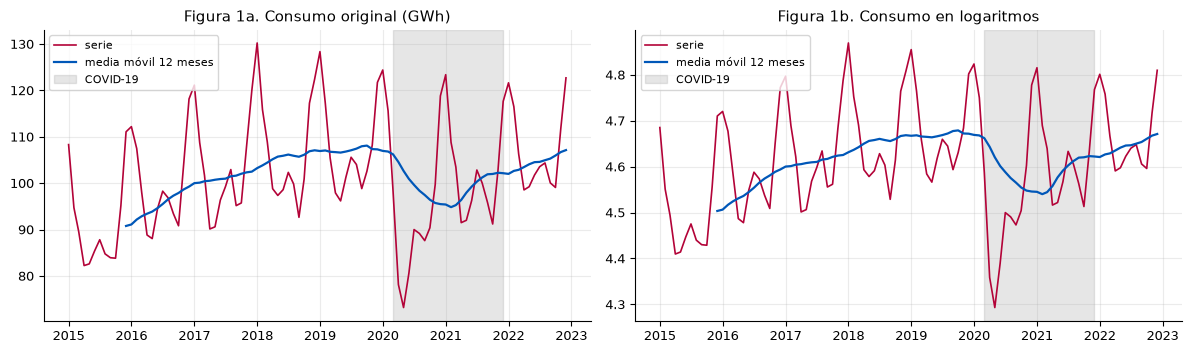

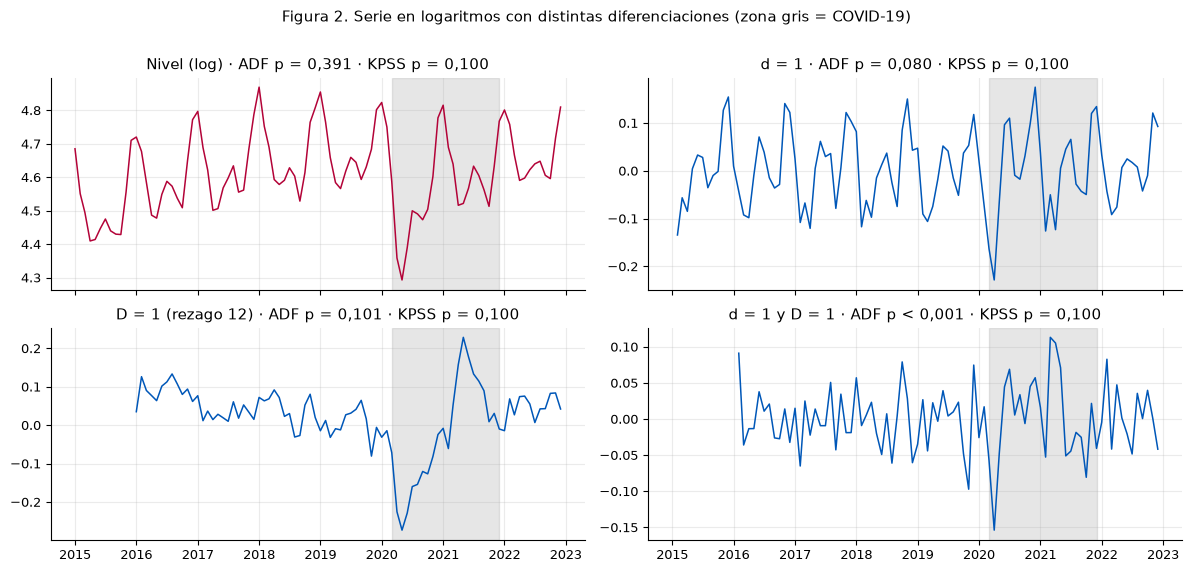

Tabla 1. Pruebas de raíz unitaria (entrenamiento 2015-2022). ADF: H0 = raíz unitaria; KPSS: H0 = estacionaria


,ADF p,KPSS p,desv. est.,ACF(12),veredicto
"Nivel (original, GWh)","0,476","0,100","12,095","0,665",Discrepante / no concluyente
Nivel (log),"0,391","0,100","0,119","0,621",Discrepante / no concluyente
d = 1,"0,080","0,100","0,080","0,757",Discrepante / no concluyente
D = 1 (rezago 12),"0,101","0,100","0,085","-0,228",Discrepante / no concluyente
d = 1 y D = 1,"0,000","0,100","0,047","-0,298",Estacionaria


Nota: statsmodels reporta el p-valor de KPSS truncado entre 0,01 y 0,10; KPSS p = 0,100 significa «0,10 o más».
λ de Box-Cox = 0,00 (IC 95 %: -1,45 a 1,49) · elasticidad de la variabilidad anual respecto del nivel (sin 2020-2021) = 0,25 · decisión de la regla: d = 1, D = 1


In [2]:
# ============================================================
# 1. Transformación (Box-Cox/log), tests ADF y KPSS y decisión de d y D  (solo datos de entrenamiento)
# ============================================================
ly_train = np.log(y_train)                                   # serie en logaritmos
_, lam, lam_ic = stats.boxcox(y_train.values, alpha=0.05)        # λ de máxima verosimilitud y su IC de 95 %
lam = float(lam)
# Elasticidad de la variabilidad anual respecto del nivel anual (sin 2020-2021, afectados por el COVID-19)
anual = y_train.groupby(y_train.index.year).agg(["mean", "std"]).drop(index=[2020, 2021])
elast = float(np.polyfit(np.log(anual["mean"]), np.log(anual["std"]), 1)[0])

def evaluar(x, reg):
    """ADF + KPSS + dos señales auxiliares (desviación estándar y ACF en el rezago 12)."""
    x = x.dropna()
    a_est, a_p = adfuller(x, regression=reg, autolag="AIC")[:2]
    k_est, k_p = kpss(x, regression=reg, nlags="auto")[:2]
    if a_p < 0.05 and k_p >= 0.05:
        ver = "Estacionaria"
    elif a_p >= 0.05 and k_p < 0.05:
        ver = "No estacionaria"
    else:
        ver = "Discrepante / no concluyente"
    return {"ADF p": a_p, "KPSS p": k_p, "desv. est.": float(x.std()),
            "ACF(12)": float(acf(x, nlags=S)[S]), "veredicto": ver}

opciones = {(0, 0): ly_train, (1, 0): ly_train.diff(), (0, 1): ly_train.diff(S), (1, 1): ly_train.diff().diff(S)}
nombres = {(0, 0): "Nivel (log)", (1, 0): "d = 1", (0, 1): "D = 1 (rezago 12)", (1, 1): "d = 1 y D = 1"}
pruebas = {k: evaluar(v, "ct" if k == (0, 0) else "c") for k, v in opciones.items()}
ref_orig = evaluar(y_train, "ct")                            # referencia: serie original sin log

# Regla fijada de antemano: menor diferenciación con veredicto "Estacionaria" y ACF(12) < 0,5
d_sel, D_sel, cumple = 1, 1, False
for k in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    if pruebas[k]["veredicto"] == "Estacionaria" and pruebas[k]["ACF(12)"] < 0.5:
        (d_sel, D_sel), cumple = k, True
        break
w = opciones[(d_sel, D_sel)].dropna()                        # serie estacionaria que se usará en la sección 2

# ---- Figura 1: serie original y en logaritmos ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, serie, tit in zip(axes, [y_train, ly_train], ["Figura 1a. Consumo original (GWh)", "Figura 1b. Consumo en logaritmos"]):
    ax.plot(serie, color=ROJO, lw=1.2, label="serie")
    ax.plot(serie.rolling(12).mean(), color=AZUL, lw=1.6, label="media móvil 12 meses")
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=0.25, label="COVID-19")
    ax.set_title(tit); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# ---- Figura 2: series con las distintas diferenciaciones ----
fig, axes = plt.subplots(2, 2, figsize=(12, 5.6), sharex=True)
for ax, (k, serie) in zip(axes.ravel(), opciones.items()):
    ax.plot(serie.dropna(), color=ROJO if k == (0, 0) else AZUL, lw=1.1)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=0.25)
    ax.set_title(f"{nombres[k]} · ADF {pp(pruebas[k]['ADF p'])} · KPSS {pp(pruebas[k]['KPSS p'])}")
fig.suptitle("Figura 2. Serie en logaritmos con distintas diferenciaciones (zona gris = COVID-19)", y=1.01, fontsize=11)
plt.tight_layout(); plt.show()

# ---- Tabla 1 ----
tab1 = pd.DataFrame({"Nivel (original, GWh)": ref_orig, **{nombres[k]: v for k, v in pruebas.items()}}).T
tab1[["ADF p", "KPSS p", "desv. est.", "ACF(12)"]] = tab1[["ADF p", "KPSS p", "desv. est.", "ACF(12)"]].astype(float).round(3)
print("Tabla 1. Pruebas de raíz unitaria (entrenamiento 2015-2022). ADF: H0 = raíz unitaria; KPSS: H0 = estacionaria")
display(tab1)
print("Nota: statsmodels reporta el p-valor de KPSS truncado entre 0,01 y 0,10; KPSS p = 0,100 significa «0,10 o más».")
print(f"λ de Box-Cox = {c(lam)} (IC 95 %: {c(lam_ic[0])} a {c(lam_ic[1])}) · elasticidad de la variabilidad anual respecto del nivel (sin 2020-2021) = {c(elast)} · decisión de la regla: d = {d_sel}, D = {D_sel}")

**Interpretación de la estacionariedad.** En este conjunto de datos, primero se evaluó la transformación con Box-Cox, obteniendo λ = 0,00 (IC 95 %: -1,45 a 1,49), por sí solo no permite decidir. Como λ ≈ 0, se trabajó con logaritmos para facilitar la interpretación de los resultados (sin 2020-2021, la elasticidad de la variabilidad anual respecto del nivel es 0,25, es decir, la variabilidad crece poco con el nivel; 0 = aditivo, 1 = multiplicativo; Figura 1) (Box y Cox, 1964; Hyndman y Athanasopoulos, 2021).

Luego, la estacionariedad se analizó con las pruebas ADF (Dickey y Fuller, 1979)  y KPSS  (Kwiatkowski et al., 1992). Según la Tabla 1, la serie en logaritmos sin diferenciar no fue concluyente (ADF p = 0,391; KPSS p = 0,100; ACF(12) = 0,62), pero con d = 1 y D = 1 se logró una serie estacionaria (ADF p < 0,001; KPSS p = 0,100; ACF(12) = -0,30). El p-valor de KPSS aparece truncado en 0,100, lo que significa 0,10 o más. La Figura 2 muestra que la variabilidad aumenta durante 2020-2021, por lo que la variable covid se incluyó como regresor. La diferenciación redujo la muestra en 13 observaciones.

## 2. Identificación y estimación de modelos
Para identificar el modelo se siguió la metodología de Box-Jenkins. Los órdenes p, q, P y Q se determinaron a partir de los gráficos ACF y PACF de la serie estacionaria (Box et al., 2015). Posteriormente, los parámetros fueron estimados mediante máxima verosimilitud (Seabold y Perktold, 2010).

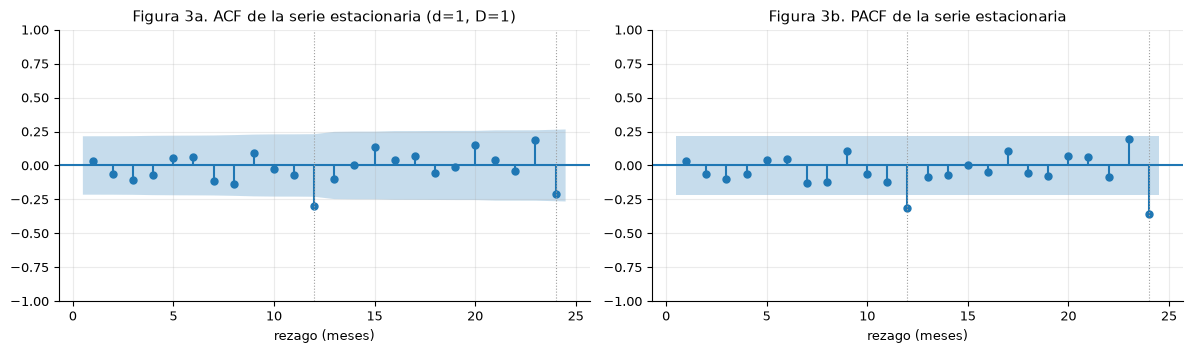

Banda 95 % = ±0,215 · rezagos ACF significativos: [12] · rezagos PACF significativos: [12, 24] · rezago 12: ACF = -0,30, PACF = -0,32


Tabla 2. Modelos candidatos estimados con el entrenamiento 2015-2022 (serie en logaritmos): parámetros, significancia, coeficientes (ee = error estándar) e invertibilidad (|raíz MA| = 1 es la frontera)


,familia,orden,parámetros,AR/MA no signif.,efecto covid (%),p covid,mín. |raíz MA|,convergió,coeficientes: estimación (ee; valor-p)
modelo,,,,,,,,,
A. SARIMA sugerido por ACF/PACF,SARIMA,"(0,1,0)(0,1,1)[12]",3,1,"-4,186","0,030","1,002",Sí,"covid = -0,043 (ee 0,020; p = 0,030); ma.S.L12 = -0,982 (ee 2,471; p = 0,691)"
B. SARIMA tipo «airline»,SARIMA,"(0,1,1)(0,1,1)[12]",4,1,"-5,987","0,000","1,002",Sí,"covid = -0,062 (ee 0,017; p < 0,001); ma.L1 = -0,205 (ee 0,086; p = 0,017); ma.S.L12 = -0,981 (ee 2,244; p = 0,662)"
"C. ARMA(1,1) sobre la serie diferenciada",ARMA,"(1,1,1)(0,1,0)[12]",4,0,"-6,021","0,002","1,013",Sí,"covid = -0,062 (ee 0,020; p = 0,002); ar.L1 = 0,808 (ee 0,086; p < 0,001); ma.L1 = -0,987 (ee 0,084; p < 0,001)"
D. ARIMA sin parte estacional (referencia),ARIMA,"(1,1,1)",5,1,"-0,781","0,787","2,444",Sí,"covid = -0,008 (ee 0,029; p = 0,787); tiempo = 0,007 (ee 0,152; p = 0,964); ar.L1 = 0,241 (ee 0,190; p = 0,204); ma.L1 = 0,409 (ee 0,177; p = 0,021)"
E. AR(1) sobre la serie diferenciada,AR,"(1,1,0)(0,1,0)[12]",3,1,"-5,737","0,018",NaN,Sí,"covid = -0,059 (ee 0,025; p = 0,018); ar.L1 = -0,048 (ee 0,108; p = 0,654)"
F. MA(1) sobre la serie diferenciada,MA,"(0,1,1)(0,1,0)[12]",3,1,"-5,902","0,013","14,677",Sí,"covid = -0,061 (ee 0,025; p = 0,013); ma.L1 = -0,068 (ee 0,105; p = 0,518)"
G. SARIMA con AR estacional (PACF en el rezago 24),SARIMA,"(0,1,1)(1,1,0)[12]",4,1,"-6,739","0,002","5,404",Sí,"covid = -0,070 (ee 0,022; p = 0,002); ma.L1 = -0,185 (ee 0,109; p = 0,089); ar.S.L12 = -0,335 (ee 0,100; p < 0,001)"


In [3]:
# ============================================================
# 2. ACF/PACF de la serie estacionaria, candidatos y estimación (entrenamiento 2015-2022)
# ============================================================
NL = 24
r_w, p_w = acf(w, nlags=NL), pacf(w, nlags=NL, method="ywm")
banda = 1.96 / np.sqrt(len(w))
sig_acf = [k for k in range(1, NL + 1) if abs(r_w[k]) > banda]
sig_pacf = [k for k in range(1, NL + 1) if abs(p_w[k]) > banda]

# ---- Figura 3: ACF y PACF ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(w, lags=NL, ax=axes[0], zero=False, title=f"Figura 3a. ACF de la serie estacionaria (d={d_sel}, D={D_sel})")
plot_pacf(w, lags=NL, ax=axes[1], zero=False, method="ywm", title="Figura 3b. PACF de la serie estacionaria")
for ax in axes:
    ax.set_xlabel("rezago (meses)")
    for k in (12, 24):
        ax.axvline(k, color=GRIS, ls=":", lw=0.8)
plt.tight_layout(); plt.show()
print(f"Banda 95 % = ±{c(banda, 3)} · rezagos ACF significativos: {sig_acf} · rezagos PACF significativos: {sig_pacf} · "
      f"rezago {S}: ACF = {c(r_w[S])}, PACF = {c(p_w[S])}")

# ---- Órdenes sugeridos por la evidencia (regla explícita) ----
def mayor_corto(sig, tope=3):
    cortos = [k for k in sig if k <= tope]
    return max(cortos) if cortos else 0

p_sug = min(mayor_corto(sig_pacf), 2)                 # AR no estacional (máx. 2 para no sobreajustar)
q_sug = min(mayor_corto(sig_acf), 2)                  # MA no estacional
Q_sug = int(S in sig_acf)                             # MA estacional si la ACF es significativa en 12
P_sug = int((S in sig_pacf) and (S not in sig_acf))   # AR estacional si solo la PACF lo es

# ---- Candidatos: (nombre, familia, (p, d, q, P, D, Q)) ----
d, D = d_sel, D_sel
candidatos = [
    ("A. SARIMA sugerido por ACF/PACF", "SARIMA", (p_sug, d, q_sug, P_sug, D, Q_sug)),
    ("B. SARIMA tipo «airline»",        "SARIMA", (0, d, 1, 0, D, 1)),
    ("C. ARMA(1,1) sobre la serie diferenciada", "ARMA", (1, d, 1, 0, D, 0)),
    ("D. ARIMA sin parte estacional (referencia)", "ARIMA", (1, 1, 1, 0, 0, 0)),
    ("E. AR(1) sobre la serie diferenciada", "AR", (1, d, 0, 0, D, 0)),
    ("F. MA(1) sobre la serie diferenciada", "MA", (0, d, 1, 0, D, 0)),
    ("G. SARIMA con AR estacional (PACF en el rezago 24)", "SARIMA", (0, d, 1, 1, D, 0)),
]
vistos, unicos = set(), []
for nom, fam, spec in candidatos:
    if spec in vistos:                                # si el sugerido repite a otro, se cambia por una variante vecina
        spec = (1, d, 0, 0, D, 1)
        nom = nom + " (variante: AR(1) + MA estacional)"
    vistos.add(spec)
    unicos.append((nom, fam, spec))
candidatos = unicos

# ---- Estimación ----
def exog_modelo(idx, d_, D_):
    """Regresores: indicador covid y, si la diferenciación total es 1, una tendencia lineal (drift)."""
    X = pd.DataFrame({"covid": covid.loc[idx]})
    if d_ + D_ == 1:
        X["tiempo"] = tiempo.loc[idx]
    return X

def ajustar(serie, spec, invertible=True):
    p, d_, q, P, D_, Q = spec
    mod = SARIMAX(serie, exog=exog_modelo(serie.index, d_, D_), order=(p, d_, q),
                  seasonal_order=(P, D_, Q, S if (P or D_ or Q) else 0), trend="c" if d_ + D_ == 0 else "n",
                  enforce_invertibility=invertible)
    return mod.fit(disp=False, maxiter=200 if invertible else 500)

resultados, filas = {}, []
for nom, fam, spec in candidatos:
    try:
        res = ajustar(ly_train, spec)
    except Exception as e:
        print(f"[aviso] {nom} no se pudo estimar: {type(e).__name__}")
        continue
    pvs = res.pvalues[[n for n in res.pvalues.index if n.startswith(("ar.", "ma."))]]
    raiz = float(np.abs(res.maroots).min()) if len(res.maroots) else np.nan
    resultados[nom] = {"spec": spec, "res": res, "k_arma": len(pvs), "raiz": raiz}
    p, d_, q, P, D_, Q = spec
    filas.append({"modelo": nom, "familia": fam, "orden": f"({p},{d_},{q})({P},{D_},{Q})[{S}]" if (P or D_ or Q) else f"({p},{d_},{q})",
                  "parámetros": len(res.params), "AR/MA no signif.": int((pvs >= 0.05).sum()),
                  "efecto covid (%)": 100 * (np.exp(res.params["covid"]) - 1), "p covid": res.pvalues["covid"],
                  "mín. |raíz MA|": raiz,
                  "convergió": "Sí" if (res.mle_retvals.get("converged", True) if getattr(res, "mle_retvals", None) else True) else "No",
                  "coeficientes: estimación (ee; valor-p)": "; ".join(
                      f"{n} = {c(res.params[n], 3)} (ee {c(res.bse[n], 3)}; {pp(res.pvalues[n])})"
                      for n in res.params.index if n != "sigma2")})
tab2 = pd.DataFrame(filas).set_index("modelo")
tab2[["efecto covid (%)", "p covid"]] = tab2[["efecto covid (%)", "p covid"]].round(3)
# Frontera de invertibilidad: si alguna raíz MA tiene módulo cercano a 1, se reestima sin la restricción
FRONTERA = 1.05
frontera = {}
for nom, r in resultados.items():
    if r["raiz"] < FRONTERA:
        ma = [k for k in r["res"].params.index if k.startswith("ma.")]
        k_ = max(ma, key=lambda k: abs(r["res"].params[k]))          # término MA más cercano a ±1
        libre = ajustar(ly_train, r["spec"], invertible=False)
        frontera[nom] = {"param": k_, "coef": r["res"].params[k_], "libre": libre.params[k_],
                         "dllf": libre.llf - r["res"].llf}
print("Tabla 2. Modelos candidatos estimados con el entrenamiento 2015-2022 (serie en logaritmos): parámetros, significancia, "
      "coeficientes (ee = error estándar) e invertibilidad (|raíz MA| = 1 es la frontera)")
display(tab2)

Después de diferenciar la serie (d = 1 y D = 1), se analizaron la ACF y la PACF (Figura 3; banda ±0,22) siguiendo a Box et al. (2015). La ACF mostró un único rezago significativo, el 12, y la PACF, los rezagos 12 y 24. Con estos resultados se identificó un modelo con p = 0, q = 0, P = 0 y Q = 1, ya que en el rezago 12 la ACF fue -0,30 y la PACF -0,32.
A partir de esta identificación se evaluaron siete modelos candidatos (Tabla 2), que cubren las familias AR, MA, ARMA, ARIMA y SARIMA: el modelo sugerido (A), el modelo «airline» (B), un ARMA(1,1) (C), un ARIMA sin componente estacional como referencia (D), un AR(1) y un MA(1) puros sobre la serie diferenciada (E y F) y un SARIMA con AR estacional (G), incluido porque la PACF también es significativa en el rezago 24. Todos incluyeron la variable covid como regresor. En el modelo A, la COVID-19 produjo una reducción estimada de 4,2 % en el consumo esperado (6,0 % en el modelo B). Los parámetros MA de los modelos A, B y C quedaron cerca del límite de invertibilidad, con raíces mínimas entre 1,002 y 1,013. Sin esta restricción, los coeficientes se aproximan a -1,00 y la log-verosimilitud varía menos de 0,03, por lo que sus errores estándar pueden no ser confiables (Box et al., 2015). Finalmente, todos los modelos se estimaron únicamente con los datos de entrenamiento, manteniendo 2023 como una validación honesta.

## 3. Selección y comparación de modelos

Los modelos se comparan con los criterios AIC (Akaike, 1974) y BIC (Schwarz, 1978), además de los errores de pronóstico RMSE y MAE para 2023 y en una validación con origen móvil (Hyndman y Athanasopoulos, 2021). Como referencia se utilizó el pronóstico ingenuo estacional.


Tabla 3. Comparación de modelos. RMSE y MAE en GWh: validación 2023 y promedio con origen móvil (2021, 2022 y 2023). AIC y BIC solo son comparables con la misma diferenciación. Elegible = supera al naive en RMSE móvil y pasa Ljung-Box (p > 0,05 en 12 y 24)


,AIC,BIC,RMSE,MAE,RMSE móvil,MAE móvil,LB p (12),LB p (24),puntaje,elegible
modelo,,,,,,,,,,
A. SARIMA sugerido por ACF/PACF,"-300,921","-293,664","7,763","7,335","5,782","5,144","0,225","0,019","1,000",No
B. SARIMA tipo «airline»,"-300,903","-291,228","7,134","6,681","7,116","6,644","0,355","0,061","2,500",Sí
"C. ARMA(1,1) sobre la serie diferenciada","-276,199","-266,524","6,687","5,885","8,299","7,182","0,108","0,047","4,500",No
D. ARIMA sin parte estacional (referencia),"-235,433","-222,664","17,482","15,966","25,900","24,234","0,000","0,000",NaN,
E. AR(1) sobre la serie diferenciada,"-272,196","-264,940","8,737","8,118","7,157","6,033","0,111","0,031","4,250",No
F. MA(1) sobre la serie diferenciada,"-272,262","-265,005","8,823","8,209","7,194","6,096","0,103","0,030","4,250",No
G. SARIMA con AR estacional (PACF en el rezago 24),"-278,941","-269,266","8,470","7,986","8,505","7,650","0,201","0,003","4,500",No
Naive estacional (referencia),NaN,NaN,"7,263","6,528","7,721","6,655",NaN,NaN,NaN,


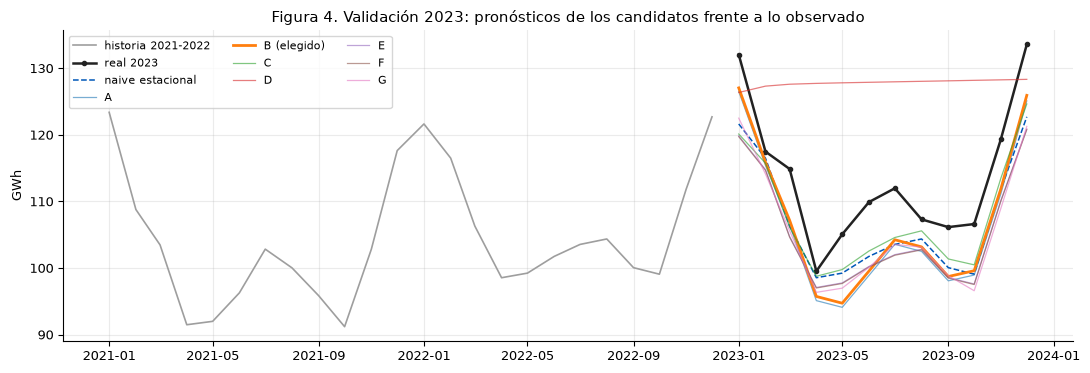

In [4]:
# Referencia obligatoria: naive estacional (repite el valor del mismo mes del año anterior)
naive_val = y["2022-01":"2022-12"].to_numpy()
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
mae  = lambda e: float(np.mean(np.abs(e)))
NAIVE = "Naive estacional (referencia)"

# ============================================================
# 3. AIC, BIC, validación 2023, validación con origen móvil (2021-2023) y Ljung-Box
# ============================================================
real = y_val.to_numpy()
filas3, pred_val = [], {}
for nom, r in resultados.items():
    p, d_, q, P, D_, Q = r["spec"]
    fc = r["res"].get_forecast(steps=12, exog=exog_modelo(y_val.index, d_, D_))
    pred = np.exp(np.asarray(fc.predicted_mean))              # se vuelve a GWh
    pred_val[nom] = pd.Series(pred, index=y_val.index)
    filas3.append({"modelo": nom, "d": d_, "D": D_, "AIC": r["res"].aic, "BIC": r["res"].bic,
                   "RMSE": rmse(real - pred), "MAE": mae(real - pred)})
filas3.append({"modelo": NAIVE, "d": np.nan, "D": np.nan, "AIC": np.nan, "BIC": np.nan,
               "RMSE": rmse(real - naive_val), "MAE": mae(real - naive_val)})
tab3 = pd.DataFrame(filas3).set_index("modelo")

# Origen móvil: se reestima con los datos hasta el año anterior y se pronostican los 12 meses siguientes.
# Empieza en 2021 porque el entrenamiento debe incluir meses con COVID-19 para estimar su efecto. 2024 no se usa.
ORIGENES = [2021, 2022, 2023]
ly_hasta_2023 = np.log(y[:"2023-12"])
errores = {nom: [] for nom in list(resultados) + [NAIVE]}
for T in ORIGENES:
    idx_T = y[f"{T}-01":f"{T}-12"].index
    real_T = y.loc[idx_T].to_numpy()
    naive_T = y[f"{T - 1}-01":f"{T - 1}-12"].to_numpy()
    errores[NAIVE].append((rmse(real_T - naive_T), mae(real_T - naive_T)))
    for nom, r in resultados.items():
        p, d_, q, P, D_, Q = r["spec"]
        res_T = r["res"] if T == 2023 else ajustar(ly_hasta_2023[:f"{T - 1}-12"], r["spec"])
        pred_T = np.exp(np.asarray(res_T.get_forecast(steps=12, exog=exog_modelo(idx_T, d_, D_)).predicted_mean))
        errores[nom].append((rmse(real_T - pred_T), mae(real_T - pred_T)))
tab3["RMSE móvil"] = [np.mean([e_[0] for e_ in errores[m]]) for m in tab3.index]
tab3["MAE móvil"] = [np.mean([e_[1] for e_ in errores[m]]) for m in tab3.index]

# Ljung-Box de los residuos de entrenamiento (rezagos 12 y 24), descontando los parámetros AR/MA
BURN = d_sel + D_sel * S
for nom, r in resultados.items():
    lb_ = acorr_ljungbox(r["res"].resid.iloc[BURN:], lags=[12, 24], model_df=r["k_arma"], return_df=True)
    tab3.loc[nom, "LB p (12)"] = lb_["lb_pvalue"].iloc[0]
    tab3.loc[nom, "LB p (24)"] = lb_["lb_pvalue"].iloc[1]

# Regla (Hoja de decisiones): mejor puntaje (rangos de AIC, BIC, RMSE móvil y MAE móvil) entre los modelos con la misma
# diferenciación que superan al naive en RMSE móvil y pasan Ljung-Box en 12 y 24; empate: menor BIC
comparable = (tab3["d"] == d_sel) & (tab3["D"] == D_sel)
tab3["puntaje"] = np.nan
tab3.loc[comparable, "puntaje"] = tab3.loc[comparable, ["AIC", "BIC", "RMSE móvil", "MAE móvil"]].rank().mean(axis=1)
rmse_naive = tab3.loc[NAIVE, "RMSE móvil"]
tab3["supera naive"] = tab3["RMSE móvil"] < rmse_naive
tab3["pasa LB"] = (tab3["LB p (12)"] > 0.05) & (tab3["LB p (24)"] > 0.05)
orden = tab3.loc[comparable].sort_values(["puntaje", "BIC"]).index.tolist()
elegibles = [m for m in orden if tab3.loc[m, "supera naive"] and tab3.loc[m, "pasa LB"]]
seleccion = elegibles[0] if elegibles else orden[0]                   # si ninguno cumple, se informa
empatados = [m for m in elegibles if tab3.loc[m, "puntaje"] == tab3.loc[seleccion, "puntaje"]]
sel = resultados[seleccion]
supera = bool(tab3.loc[seleccion, "supera naive"])
tab3["elegible"] = np.where(comparable, np.where(tab3["supera naive"] & tab3["pasa LB"], "Sí", "No"), "")
print("Tabla 3. Comparación de modelos. RMSE y MAE en GWh: validación 2023 y promedio con origen móvil (2021, 2022 y 2023). "
      "AIC y BIC solo son comparables con la misma diferenciación. Elegible = supera al naive en RMSE móvil y pasa Ljung-Box (p > 0,05 en 12 y 24)")
nivel_movil = float(y[f"{ORIGENES[0]}-01":f"{ORIGENES[-1]}-12"].mean())
print(f"Consumo medio mensual {ORIGENES[0]}-{ORIGENES[-1]} = {c(nivel_movil)} GWh · MAE móvil del elegido = {c(100 * tab3.loc[seleccion, 'MAE móvil'] / nivel_movil, 1)} % "
      f"de ese nivel (naive estacional: {c(100 * tab3.loc[NAIVE, 'MAE móvil'] / nivel_movil, 1)} %)")
display(tab3[["AIC", "BIC", "RMSE", "MAE", "RMSE móvil", "MAE móvil", "LB p (12)", "LB p (24)", "puntaje", "elegible"]].round(3))

# ---- Figura 4: pronósticos de validación ----
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(y["2021-01":"2022-12"], color=GRIS, lw=1.2, label="historia 2021-2022")
ax.plot(y_val, color=NEGRO, lw=1.8, marker="o", ms=3, label="real 2023")
ax.plot(y_val.index, naive_val, color=AZUL, lw=1.1, ls="--", label="naive estacional")
for nom, s_ in pred_val.items():
    ax.plot(s_, lw=2.0 if nom == seleccion else 0.9, alpha=1 if nom == seleccion else 0.6, label=nom.split(".")[0] + (" (elegido)" if nom == seleccion else ""))
ax.set_ylabel("GWh"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Figura 4. Validación 2023: pronósticos de los candidatos frente a lo observado")
plt.tight_layout(); plt.show()

Los modelos se compararon mediante los criterios AIC (Akaike, 1974) y BIC (Schwarz, 1978), junto con los indicadores RMSE y MAE. Además, se aplicó una validación con origen móvil para 2021-2023, reestimando cada modelo con la información disponible hasta el año anterior (Hyndman y Athanasopoulos, 2021).

El modelo A obtuvo el mejor puntaje (RMSE móvil = 5,78 GWh), pero fue descartado por presentar autocorrelación en los residuos (Ljung-Box p = 0,019 en el rezago 24). Los modelos E y F también superaron al naive en RMSE móvil (7,16 y 7,19 GWh), pero, al igual que C y G, dejaron autocorrelación en el rezago 24, por lo que tampoco fueron elegibles. Finalmente, se seleccionó el **modelo B** (SARIMA tipo «airline»), con AIC = -300,9, BIC = -291,2 y RMSE móvil = 7,12 GWh. Frente al naive estacional (7,72 GWh), redujo el RMSE en 7,8 %; en MAE queda prácticamente igual (6,64 frente a 6,66 GWh). El ARIMA sin estacionalidad alcanzó un RMSE móvil de 25,90 GWh, evidenciando la importancia de la componente estacional.

## 4. Diagnóstico de residuos y validación de supuestos

Se valida que los residuos del modelo elegido se comporten como ruido blanco: autocorrelación con Ljung-Box (Ljung y Box, 1978), normalidad con Jarque-Bera (Jarque y Bera, 1987) y Shapiro-Wilk (Shapiro y Wilk, 1965), y homocedasticidad con ARCH-LM (Engle, 1982).

Tabla 4. Pruebas sobre los residuos de B. SARIMA tipo «airline» (n = 83; Ljung-Box con 2 parámetros AR/MA descontados)


,prueba,estadístico,valor-p,conclusión (5 %)
supuesto,,,,
Sin autocorrelación,"Ljung-Box, rezago 12","11,034","0,355",Cumple
Sin autocorrelación,"Ljung-Box, rezago 24","33,085","0,061",Cumple
Normalidad,Jarque-Bera,"13,402","0,001",No cumple
Normalidad,Shapiro-Wilk,"0,964","0,019",No cumple
Homocedasticidad,ARCH-LM (12 rezagos),"9,734","0,639",Cumple
Homocedasticidad,F de varianzas (2.ª / 1.ª mitad),"1,446","0,246",Cumple
Normalidad sin mar-jun 2020,Jarque-Bera,"3,074","0,215",Cumple
Normalidad sin mar-jun 2020,Shapiro-Wilk,"0,974","0,111",Cumple
Intervalos calibrados,"Cobertura del intervalo de predicción del 95 % en el origen móvil (%, 36 meses; binomial)","94,444","0,701",Cumple


Asimetría = -0,36 · curtosis en exceso = 1,83 (normal: 0 y 0)
Sensibilidad: con un indicador adicional para abril-junio de 2020, Jarque-Bera p = 0,226 y Ljung-Box (rezago 24) p = 0,039


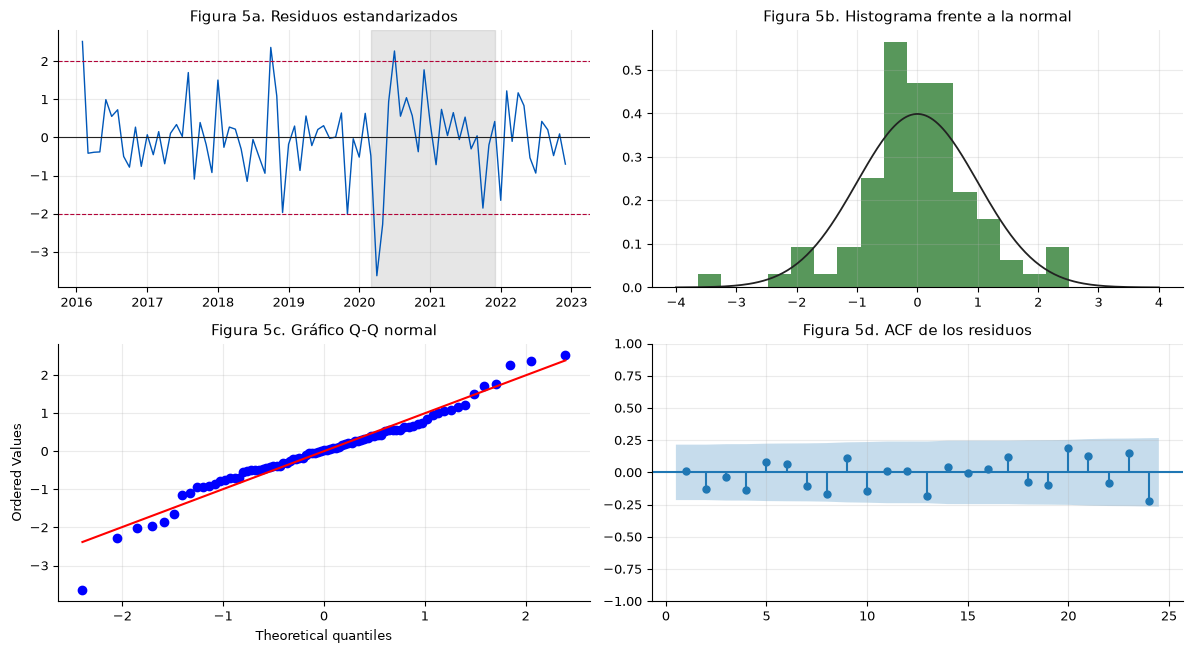

In [5]:
# ============================================================
# 4. Diagnóstico del modelo seleccionado: Ljung-Box (12 y 24), normalidad y ARCH-LM
# ============================================================
res_sel = sel["res"]
BURN = d_sel + D_sel * S                                   # los primeros residuos están afectados por la diferenciación
e = res_sel.resid.iloc[BURN:]
z = (e - e.mean()) / e.std()
k_arma = sel["k_arma"]

lb = acorr_ljungbox(e, lags=[12, 24], model_df=k_arma, return_df=True)
jb_est, jb_p = stats.jarque_bera(e)
sw_est, sw_p = stats.shapiro(e)
arch_lm, arch_p, _, _ = het_arch(e, nlags=12)
mitad = len(e) // 2
v1, v2 = float(e.iloc[:mitad].var(ddof=1)), float(e.iloc[mitad:].var(ddof=1))
F = v2 / v1
p_F = 2 * min(stats.f.cdf(F, len(e) - mitad - 1, mitad - 1), 1 - stats.f.cdf(F, len(e) - mitad - 1, mitad - 1))

# ¿De dónde viene la falta de normalidad? Forma de la distribución y pruebas sin el inicio del COVID-19 (mar-jun 2020)
asim, curt = float(stats.skew(e)), float(stats.kurtosis(e))             # curtosis en exceso (normal = 0)
INICIO_COVID = (e.index >= pd.Timestamp("2020-03-01")) & (e.index <= pd.Timestamp("2020-06-01"))
jb_p_sin, sw_p_sin = float(stats.jarque_bera(e[~INICIO_COVID])[1]), float(stats.shapiro(e[~INICIO_COVID])[1])

# ¿Están bien calibrados los intervalos? Cobertura empírica del IC 95 % en el origen móvil (sección 3)
p_, d_, q_, P_, D__, Q_ = sel["spec"]
dentro = []
for T in ORIGENES:
    idx_T = y[f"{T}-01":f"{T}-12"].index
    res_T = res_sel if T == 2023 else ajustar(ly_hasta_2023[:f"{T - 1}-12"], sel["spec"])
    ic_T = np.exp(np.asarray(res_T.get_forecast(steps=12, exog=exog_modelo(idx_T, d_, D__)).conf_int(alpha=0.05)))
    real_T = y.loc[idx_T].to_numpy()
    dentro += list((real_T >= ic_T[:, 0]) & (real_T <= ic_T[:, 1]))
cobertura = 100 * float(np.mean(dentro))
p_cob = float(stats.binomtest(int(np.sum(dentro)), len(dentro), 0.95).pvalue)   # H0: la cobertura real es 95 %

# Sensibilidad: indicador adicional para el mínimo de abril a junio de 2020
pico = pd.Series(((ly_train.index >= "2020-04-01") & (ly_train.index <= "2020-06-01")).astype(float), index=ly_train.index)
X_pico = exog_modelo(ly_train.index, d_, D__).assign(pico=pico)
res_pico = SARIMAX(ly_train, exog=X_pico, order=(p_, d_, q_), seasonal_order=(P_, D__, Q_, S if (P_ or D__ or Q_) else 0),
                   trend="c" if d_ + D__ == 0 else "n").fit(disp=False, maxiter=200)
e_pico = res_pico.resid.iloc[BURN:]
sens_pico = {"jb_p": float(stats.jarque_bera(e_pico)[1]),
             "lb24_p": float(acorr_ljungbox(e_pico, lags=[24], model_df=k_arma, return_df=True)["lb_pvalue"].iloc[0])}

tab4 = pd.DataFrame([
    {"supuesto": "Sin autocorrelación", "prueba": "Ljung-Box, rezago 12", "estadístico": lb["lb_stat"].iloc[0], "valor-p": lb["lb_pvalue"].iloc[0]},
    {"supuesto": "Sin autocorrelación", "prueba": "Ljung-Box, rezago 24", "estadístico": lb["lb_stat"].iloc[1], "valor-p": lb["lb_pvalue"].iloc[1]},
    {"supuesto": "Normalidad", "prueba": "Jarque-Bera", "estadístico": jb_est, "valor-p": jb_p},
    {"supuesto": "Normalidad", "prueba": "Shapiro-Wilk", "estadístico": sw_est, "valor-p": sw_p},
    {"supuesto": "Homocedasticidad", "prueba": "ARCH-LM (12 rezagos)", "estadístico": arch_lm, "valor-p": arch_p},
    {"supuesto": "Homocedasticidad", "prueba": "F de varianzas (2.ª / 1.ª mitad)", "estadístico": F, "valor-p": p_F},
    {"supuesto": "Normalidad sin mar-jun 2020", "prueba": "Jarque-Bera", "estadístico": float(stats.jarque_bera(e[~INICIO_COVID])[0]), "valor-p": jb_p_sin},
    {"supuesto": "Normalidad sin mar-jun 2020", "prueba": "Shapiro-Wilk", "estadístico": float(stats.shapiro(e[~INICIO_COVID])[0]), "valor-p": sw_p_sin},
    {"supuesto": "Intervalos calibrados", "prueba": f"Cobertura del intervalo de predicción del 95 % en el origen móvil (%, {len(dentro)} meses; binomial)", "estadístico": cobertura, "valor-p": p_cob},
])
tab4["conclusión (5 %)"] = np.where(tab4["valor-p"] > 0.05, "Cumple", "No cumple")
tab4[["estadístico", "valor-p"]] = tab4[["estadístico", "valor-p"]].round(3)
print(f"Tabla 4. Pruebas sobre los residuos de {seleccion} (n = {len(e)}; Ljung-Box con {k_arma} parámetro{'s' if k_arma != 1 else ''} AR/MA descontado{'s' if k_arma != 1 else ''})")
display(tab4.set_index("supuesto"))
print(f"Asimetría = {c(asim)} · curtosis en exceso = {c(curt)} (normal: 0 y 0)")
print(f"Sensibilidad: con un indicador adicional para abril-junio de 2020, Jarque-Bera {pp(sens_pico['jb_p'])} y Ljung-Box (rezago 24) {pp(sens_pico['lb24_p'])}")

# ---- Figura 5: residuos, histograma, Q-Q y ACF ----
fig, axes = plt.subplots(2, 2, figsize=(12, 6.6))
axes[0, 0].plot(z, color=AZUL, lw=1.0); axes[0, 0].axhline(0, color=NEGRO, lw=0.8)
for lim in (-2, 2):
    axes[0, 0].axhline(lim, color=ROJO, ls="--", lw=0.8)
axes[0, 0].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=0.25)
axes[0, 0].set_title("Figura 5a. Residuos estandarizados")
axes[0, 1].hist(z, bins=16, density=True, color=VERDE, alpha=0.8)
xs = np.linspace(-4, 4, 200); axes[0, 1].plot(xs, stats.norm.pdf(xs), color=NEGRO, lw=1.3)
axes[0, 1].set_title("Figura 5b. Histograma frente a la normal")
stats.probplot(z, dist="norm", plot=axes[1, 0]); axes[1, 0].set_title("Figura 5c. Gráfico Q-Q normal")
plot_acf(e, lags=24, ax=axes[1, 1], zero=False, title="Figura 5d. ACF de los residuos")
plt.tight_layout(); plt.show()

Se analizaron los residuos del modelo mediante pruebas de autocorrelación, normalidad y homocedasticidad (Tabla 4 y Figura 5).
La prueba de Ljung-Box (Ljung y Box, 1978) dio p = 0,355 en el rezago 12 y p = 0,061 en el rezago 24. Como ambos valores son mayores que 0,05, no se rechaza que los residuos sean ruido blanco, aunque el valor del rezago 24 está cerca del umbral.
En las pruebas de normalidad, Jarque-Bera (Jarque y Bera, 1987) obtuvo p = 0,001 y Shapiro-Wilk (Shapiro y Wilk, 1965) p = 0,019, por lo que los residuos no siguen una distribución normal. Sin embargo, al excluir marzo-junio de 2020, los valores aumentaron a 0,215 y 0,111, mostrando que el efecto se concentra al inicio de la COVID-19.
La prueba ARCH-LM (Engle, 1982) obtuvo p = 0,639 y el test F entre mitades p = 0,246, sin evidencia de cambios en la varianza.
En general, los resultados indican que el modelo es adecuado para realizar pronósticos. Además, el intervalo de predicción del 95 % cubrió el 94,4 % de los 36 meses evaluados en el origen móvil (prueba binomial, p = 0,701), lo que muestra un buen desempeño.

## 5. Discusión

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

**PROPUESTA PENDIENTE DE REESCRITURA** — Texto de apoyo generado con IA. Reescribir con mis palabras, sin acortarlo (la extensión depende de esta sección), quitar este recuadro y, si se conserva parte de esta redacción, mencionarlo en la declaración de uso de IA.

**Candidatos no elegibles.** La regla de selección privilegia la validez de los residuos por sobre la precisión bruta, y eso explica por qué el modelo elegido no es el que mejor pronostica. El modelo A tuvo el menor RMSE móvil (5,78 GWh), pero sus residuos conservan autocorrelación en el rezago 24 (Ljung-Box p = 0,019): parte de la estructura de la serie quedó sin modelar y sus intervalos de predicción no serían confiables. Algo similar ocurre con E y F, que incluso obtienen un MAE móvil menor que B (6,03 y 6,10 frente a 6,64 GWh), pero también dejan autocorrelación (p = 0,031 y 0,030). C y G fallan por partida doble: no superan al ingenuo estacional (RMSE móvil de 8,30 y 8,51 GWh) y dejan autocorrelación (p = 0,047 y 0,003). El ARIMA sin parte estacional (25,90 GWh) confirma que la estacionalidad anual es el rasgo dominante de la serie. En síntesis, B es el único candidato que combina residuos sin autocorrelación con un error menor que la referencia mínima, aunque esa ventaja es moderada.

**Indicador para abril-junio de 2020.** Agregar este indicador corrige la falta de normalidad (Jarque-Bera p = 0,226 frente a 0,001), pero introduce autocorrelación en el rezago 24 (Ljung-Box p = 0,039). Como la regla exige residuos sin autocorrelación y los intervalos actuales ya tienen una cobertura empírica de 94,4 % (prueba binomial p = 0,701), se mantiene el modelo B sin ese indicador. La normalidad imperfecta afecta sobre todo a los intervalos en los meses extremos, no al pronóstico puntual.

**Implicancias para la contratación de energía.** En la validación con origen móvil, B se equivoca en promedio 6,64 GWh por mes, cerca del 6,2 % del consumo mensual medio de 2021-2023 (107,65 GWh). Su ventaja sobre el ingenuo estacional está en los errores grandes (RMSE 7,8 % menor), no en el error típico (MAE prácticamente igual). Para la distribuidora esto sugiere tres usos: tomar el pronóstico de B como base de la compra mensual, usar el intervalo de predicción del 95 % como margen de seguridad para no quedar corta en los meses de mayor consumo y reestimar el modelo cada año con el dato nuevo, como en la validación con origen móvil. Por último, el efecto del COVID-19 en B fue de −6,0 % sobre el nivel esperado: un shock de esa magnitud no lo anticipa ningún modelo univariado, por lo que, ante eventos similares, el pronóstico debe complementarse con información externa, como la temperatura o la actividad del comercio.

</div>

## Conclusiones

1. La serie en logaritmos sin diferenciar no mostró resultados claros de estacionariedad (ADF p = 0,391; KPSS p = 0,100) y mantuvo una fuerte estacionalidad (ACF(12) = 0,62). Después de aplicar d = 1 y D = 1, la serie se volvió estacionaria.
2. Con la ACF y la PACF se propusieron siete modelos de las familias AR, MA, ARMA, ARIMA y SARIMA, todos con la variable covid. El efecto del COVID-19 se ve en la Tabla 2.
3. El modelo seleccionado fue el B (SARIMA tipo «airline»). En la validación con origen móvil obtuvo un RMSE de 7,12 GWh, mejor que el pronóstico ingenuo estacional (7,72 GWh).
4. En los residuos, Ljung-Box no detecta autocorrelación, la normalidad no se cumplió y la homocedasticidad sí se cumplió. En conjunto, el modelo fue adecuado para pronosticar.
5. Limitaciones: la validación incluye solo tres años, el COVID-19 se representó con un único indicador y no se consideró la temperatura. Como mejora, podría incorporarse un indicador para abril-junio de 2020 (Jarque-Bera p = 0,226; Ljung-Box p = 0,039) o utilizar un modelo SARIMAX con temperatura.

## Referencias (APA)

Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705

Box, G. E. P., y Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Dickey, D. A., y Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Jarque, C. M., y Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., y Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root: How sure are we that economic time series have a unit root? *Journal of Econometrics, 54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136

Seabold, S., y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Shapiro, S. S., y Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.

## Declaración de uso de asistentes de IA

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó asistentes de IA en esta entrega? | Sí. Se usó como apoyo y para preparar un borrador de esta entrega. |
| ¿En qué partes específicas? | Se utilizó como borrador y apoyo para el código de las cuatro secciones técnicas. Las interpretaciones fueron realizadas mediante análisis propio, se reescribieron las conclusiones de cada una de las secciones y se estableció su concordancia con la Hoja de decisiones. |
| ¿Qué verificó de forma independiente y cómo? | Se ejecutó el notebook completo desde un kernel reiniciado en VS Code y se verificó que fuese autocontenido. Además, revisé e interpreté cada resultado y verifiqué que cada texto descrito coincidiera con los valores de cada tabla de resultados. Por último, comprobé el trabajo con la rúbrica publicada en Canvas antes de la entrega. |